First 5 rows:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Dataset Shape: (768, 9)

First 5 test predictions: [0 0 0 0 1]
Initial Test Accuracy (k=3): 66.88%

5-Fold CV Scores: [0.68181818 0.69480519 0.75324675 0.75163399 0.68627451]
CV Scores Mean: 0.7136

Optimal value for 'n_neighbors': 14
Mean CV score for optimal k: 0.7579

--- Evaluation M

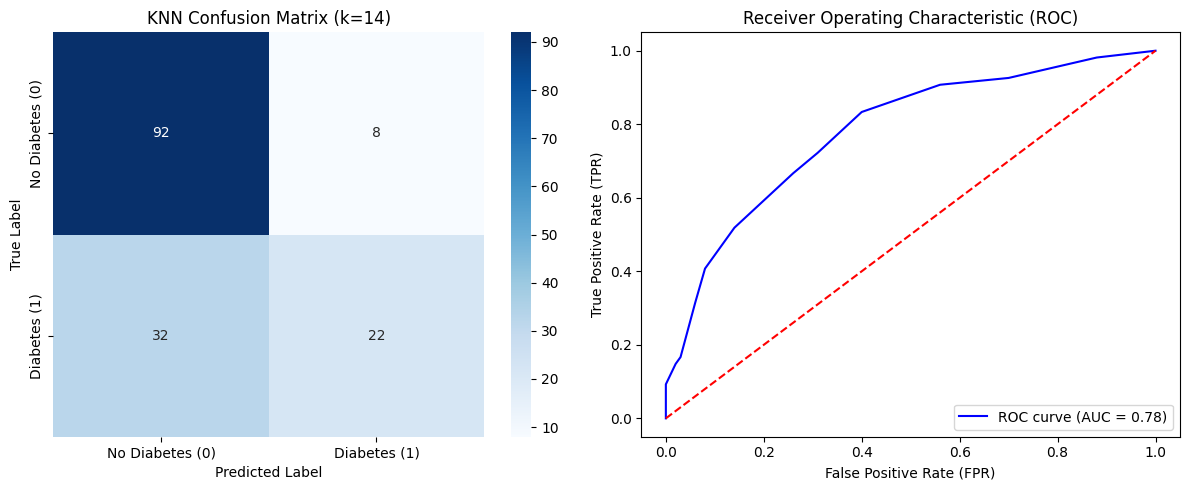

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    roc_curve,
    roc_auc_score
)

# -----------------------------------------------------------
# 1. Read the Dataset
# -----------------------------------------------------------
# Dataset link: https://www.kaggle.com/datasets/shrutimechlearn/step-by-step-diabetes-classification-knn-detailed
df = pd.read_csv('diabetes.csv')

print("First 5 rows:")
print(df.head())

print("\nDataset Shape:", df.shape)  # Typically (768, 9)

# -----------------------------------------------------------
# 2. Split Features and Target
# -----------------------------------------------------------
# In standard diabetes datasets, the target is named 'Outcome' or 'diabetes'
target_col = 'Outcome' if 'Outcome' in df.columns else 'diabetes'

X = df.drop(columns=[target_col])
y = df[target_col].values

# -----------------------------------------------------------
# 3. Train-Test Split
# -----------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1, stratify=y
)

# -----------------------------------------------------------
# 4. Train Initial KNN Model (k = 3)
# -----------------------------------------------------------
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

# First 5 predictions on test set
print("\nFirst 5 test predictions:", knn.predict(X_test)[0:5])
print(f"Initial Test Accuracy (k=3): {knn.score(X_test, y_test) * 100:.2f}%")

# -----------------------------------------------------------
# 5. 5-Fold Cross Validation
# -----------------------------------------------------------
knn_cv = KNeighborsClassifier(n_neighbors=3)
cv_scores = cross_val_score(knn_cv, X, y, cv=5)
print("\n5-Fold CV Scores:", cv_scores)
print(f"CV Scores Mean: {np.mean(cv_scores):.4f}")

# -----------------------------------------------------------
# 6. Hyperparameter Tuning using GridSearchCV
# -----------------------------------------------------------
knn2 = KNeighborsClassifier()
param_grid = {'n_neighbors': np.arange(1, 25)}

knn_gscv = GridSearchCV(knn2, param_grid, cv=5)
knn_gscv.fit(X, y)

best_k = knn_gscv.best_params_['n_neighbors']
print(f"\nOptimal value for 'n_neighbors': {best_k}")
print(f"Mean CV score for optimal k: {knn_gscv.best_score_:.4f}")

# -----------------------------------------------------------
# 7. Evaluate Optimal Model on Test Set
# -----------------------------------------------------------
best_knn = KNeighborsClassifier(n_neighbors=best_k)
best_knn.fit(X_train, y_train)
y_pred = best_knn.predict(X_test)
y_pred_proba = best_knn.predict_proba(X_test)[:, 1]

# Calculations of Evaluation Metrics
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

accuracy = accuracy_score(y_test, y_pred)
error_rate = 1.0 - accuracy  # or (fp + fn) / (tp + tn + fp + fn)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print("\n--- Evaluation Metrics on Test Set ---")
print(f"Confusion Matrix:\n{cm}")
print(f"Accuracy   : {accuracy:.4f}")
print(f"Error Rate : {error_rate:.4f}")
print(f"Precision  : {precision:.4f}")
print(f"Recall     : {recall:.4f}")
print(f"F1-Score   : {f1:.4f}")
print(f"ROC AUC    : {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# -----------------------------------------------------------
# 8. Visualizations: Confusion Matrix & ROC Curve
# -----------------------------------------------------------
plt.figure(figsize=(12, 5))

# Plot Confusion Matrix
plt.subplot(1, 2, 1)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Diabetes (0)', 'Diabetes (1)'],
            yticklabels=['No Diabetes (0)', 'Diabetes (1)'])
plt.title(f"KNN Confusion Matrix (k={best_k})")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

# Plot ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
plt.subplot(1, 2, 2)
plt.plot(fpr, tpr, color='blue', label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc='lower right')

plt.tight_layout()
plt.show()